# Cúmulos estelares jóvenes vistos por JWST/NIRCam
### Actividad práctica — Maestría · Datos de PHANGS-JWST

**Objetivos.** Al terminar esta actividad podrás:

1. Explicar qué es NIRCam, qué filtros usa PHANGS y qué traza cada uno.
2. Describir, a grandes rasgos, cómo se pasa de las rampas crudas del detector a un mosaico calibrado (sin tener que reducir datos).
3. Leer un archivo FITS de JWST: extensiones, encabezados, unidades (MJy/sr) y mapas de peso.
4. Hacer fotometría de apertura, convertir a magnitudes AB y entender la corrección de apertura.
5. Usar colores en el infrarrojo cercano para distinguir cúmulos **embebidos en polvo** de cúmulos **expuestos**.
6. Ver cómo cambia la apariencia de un mismo cúmulo de una banda a otra.

**Estructura** (≈ 3 h):

| Parte | Tema | Tiempo |
|---|---|---|
| 0 | Configuración y acceso a los datos | 10 min |
| 1 | JWST, NIRCam y los filtros de PHANGS | 20 min |
| 2 | ¿Cómo se reducen los datos? (lectura guiada + exploración del FITS) | 35 min |
| 3 | Unidades e imágenes en las cuatro bandas | 25 min |
| 4 | Fotometría de apertura | 45 min |
| 5 | El catálogo: diagramas color–magnitud y color–color | 30 min |
| 6 | Un cúmulo, cuatro bandas | 20 min |

Las celdas marcadas con ✏️ contienen **preguntas** que debes responder en una celda de texto debajo. Las marcadas con 🔧 tienen parámetros que puedes cambiar para experimentar.

---
## Parte 0 · Configuración

> **Nota para el docente.** La celda de configuración apunta a los datos. Hay tres opciones:
> * `"drive"`: las imágenes y el catálogo están en una carpeta de Google Drive compartida con el grupo (lo más rápido para clase). Cada estudiante debe añadir un acceso directo a esa carpeta en su *Mi unidad*.
> * `"url"`: los archivos están en un servidor web público (`URL_BASE`).
> * `"mast"`: las imágenes se descargan directamente del archivo público de PHANGS-JWST en MAST (HLSP, DR1 v1p1). El catálogo debe darse por Drive o URL.
>
> Los mosaicos completos pesan cientos de MB por banda. Si se usa `"mast"` en clase, conviene correr una vez la celda opcional **«Guardar recortes»** (al final de la Parte 3) y compartir los recortes pequeños por Drive.

Ejecuta las celdas en orden con **Shift + Enter**.

In [1]:
# Paquetes que no vienen preinstalados en Colab
!pip -q install photutils astroquery reproject

In [2]:
import os, warnings
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.stats import sigma_clipped_stats, SigmaClip
from astropy.utils.data import download_file
from astropy.visualization import ImageNormalize, AsinhStretch, PercentileInterval, LogStretch
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats

warnings.simplefilter("ignore", FITSFixedWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower", "image.cmap": "gray_r"})
print("Listo.")

Listo.


In [4]:
# ============================ 🔧 CONFIGURACIÓN (la edita el docente) ============================
GALAXIA  = "ngc0628"                          # nombre como en PHANGS: ngc0628, ngc1365, ic5332, ...
FILTROS  = ["F200W", "F300M", "F335M", "F360M"]  # bandas NIRCam de PHANGS (onda corta primero)
RGB      = ("F335M", "F300M", "F200W")         # (rojo, verde, azul) para la imagen en color

FUENTE_DATOS = "mast"                        # "drive", "url" o "mast"
DRIVE_DIR    = "/content/drive/MyDrive/PHANGS_JWST_actividad"
URL_BASE     = ""                             # solo si FUENTE_DATOS == "url"
LOCAL_DIR    = "./datos"               # dónde se guardan las descargas

# Nombre de las imágenes (convención de MAST). Si usas recortes propios, cambia el patrón,
# p. ej. "{gal}_{filt}_recorte.fits"
PATRON_IMAGEN = "hlsp_phangs-jwst_jwst_nircam_{gal}_{filt}_v1p1_img.fits"

# Catálogo de fotometría NIRCam (FITS o CSV). Puede ser un nombre dentro de DRIVE_DIR/URL_BASE,
# una ruta absoluta o una URL. None = la libreta detecta fuentes por su cuenta.
ARCHIVO_CATALOGO = "catalogo_nircam.fits"

# Nombres de columnas del catálogo (ajústalos; la celda de lectura te muestra las columnas disponibles)
COLS = {
    "id":  "ID",
    "ra":  "RA",          # grados
    "dec": "DEC",         # grados
    "mag": {f: f"mag_{f}"    for f in FILTROS},   # magnitudes AB
    "err": {f: f"magerr_{f}" for f in FILTROS},
    "clase": None,        # columna con clase/tipo de objeto, si existe (si no, None)
}

# Región de trabajo
CENTRO_RECORTE = None            # (RA, Dec) en grados; None = centro del mosaico
TAM_RECORTE    = 90 * u.arcsec   # lado del recorte
# ===============================================================================================

In [5]:
os.makedirs(LOCAL_DIR, exist_ok=True)
if FUENTE_DATOS == "drive":
    from google.colab import drive
    drive.mount("/content/drive")

_PRODUCTOS_MAST = None
def _descargar_mast(nombre):
    # Descarga un producto HLSP de PHANGS-JWST desde MAST (solo si no está ya en disco).
    global _PRODUCTOS_MAST
    from astroquery.mast import Observations
    destino = os.path.join(LOCAL_DIR, nombre)
    if os.path.exists(destino):
        return destino
    if _PRODUCTOS_MAST is None:
        print("Consultando MAST (solo la primera vez; puede tardar un minuto)...")
        obs = Observations.query_criteria(provenance_name="PHANGS-JWST")
        _PRODUCTOS_MAST = Observations.get_product_list(obs)
    sel = _PRODUCTOS_MAST[_PRODUCTOS_MAST["productFilename"] == nombre]
    if len(sel) == 0:
        raise FileNotFoundError(f"{nombre} no está en MAST. Revisa GALAXIA y PATRON_IMAGEN.")
    print(f"Descargando {nombre} ...")
    man = Observations.download_products(sel[:1], download_dir=LOCAL_DIR, flat=True)
    return str(man["Local Path"][0])

def resolver(nombre):
    # Convierte un nombre de archivo en una ruta local, según FUENTE_DATOS.
    if nombre.startswith("http"):
        return download_file(nombre, cache=True, show_progress=True)
    if os.path.isabs(nombre):
        return nombre
    if FUENTE_DATOS == "drive":
        ruta = os.path.join(DRIVE_DIR, nombre)
        if not os.path.exists(ruta):
            raise FileNotFoundError(f"No encuentro {ruta}. ¿Agregaste el acceso directo a la carpeta en tu Drive?")
        return ruta
    if FUENTE_DATOS == "url":
        return download_file(URL_BASE.rstrip("/") + "/" + nombre, cache=True, show_progress=True)
    if FUENTE_DATOS == "mast":
        return _descargar_mast(nombre)
    raise ValueError("FUENTE_DATOS debe ser 'drive', 'url' o 'mast'")

RUTAS = {f: resolver(PATRON_IMAGEN.format(gal=GALAXIA, filt=f.lower())) for f in FILTROS}
for f, r in RUTAS.items():
    print(f"{f}: {r}  ({os.path.getsize(r)/1e6:.0f} MB)")

Consultando MAST (solo la primera vez; puede tardar un minuto)...
Descargando hlsp_phangs-jwst_jwst_nircam_ngc0628_f200w_v1p1_img.fits ...


Descargando hlsp_phangs-jwst_jwst_nircam_ngc0628_f300m_v1p1_img.fits ...


Descargando hlsp_phangs-jwst_jwst_nircam_ngc0628_f335m_v1p1_img.fits ...


Descargando hlsp_phangs-jwst_jwst_nircam_ngc0628_f360m_v1p1_img.fits ...


F200W: datos/hlsp_phangs-jwst_jwst_nircam_ngc0628_f200w_v1p1_img.fits  (2763 MB)
F300M: datos/hlsp_phangs-jwst_jwst_nircam_ngc0628_f300m_v1p1_img.fits  (451 MB)
F335M: datos/hlsp_phangs-jwst_jwst_nircam_ngc0628_f335m_v1p1_img.fits  (451 MB)
F360M: datos/hlsp_phangs-jwst_jwst_nircam_ngc0628_f360m_v1p1_img.fits  (451 MB)


---
## Parte 1 · JWST, NIRCam y los filtros de PHANGS

**JWST** es un telescopio de 6.5 m optimizado para el infrarrojo (0.6–28 µm). Está en el punto L2 y se enfría pasivamente detrás de un parasol, porque a estas longitudes de onda *todo lo tibio brilla*, incluido el propio telescopio.

**NIRCam** (*Near InfraRed Camera*) es su cámara de 0.6–5 µm. Puntos clave:

* Tiene **dos canales que observan simultáneamente** el mismo campo gracias a un divisor dicroico:
  * **Onda corta (SW, 0.6–2.3 µm):** 4 detectores por módulo, píxel de ≈0.031″.
  * **Onda larga (LW, 2.4–5 µm):** 1 detector por módulo, píxel de ≈0.063″.
* Hay dos módulos idénticos (A y B), cada uno cubre ≈2.2′×2.2′.
* Los detectores son HgCdTe que se leen de forma **no destructiva**: la carga se va midiendo muchas veces mientras se acumula (una «rampa»). Esto es muy distinto de un CCD óptico y lo veremos en la Parte 2.
* El tamaño de la PSF crece con la longitud de onda (difracción: FWHM ∝ λ/D), y tiene **seis picos de difracción** por la forma hexagonal del espejo segmentado.

**PHANGS-JWST** (Ciclo 1, Lee et al. 2023) observó 19 galaxias espirales cercanas con 4 filtros de NIRCam y 4 de MIRI. Aquí usamos los de NIRCam:

| Filtro | Canal | λ pivote (µm, aprox.) | FWHM PSF (″, aprox.) | ¿Qué traza? |
|---|---|---|---|---|
| F200W | SW | 2.0 | 0.07 | Luz estelar (≈ banda K); poco afectada por extinción |
| F300M | LW | 3.0 | 0.10 | Continuo estelar + polvo caliente; referencia para el PAH |
| F335M | LW | 3.35 | 0.11 | **Rasgo de PAH a 3.3 µm** + continuo |
| F360M | LW | 3.6 | 0.12 | Continuo (estrellas + polvo caliente) |

«W» = filtro ancho (*wide*), «M» = intermedio (*medium*). Los PAH (hidrocarburos aromáticos policíclicos) son moléculas grandes que emiten cuando absorben fotones UV: marcan regiones con polvo iluminado por estrellas jóvenes.

> En los diagramas usamos la notación **K ≡ F200W**, de modo que el color F200W−F300M se escribe K−F300M.

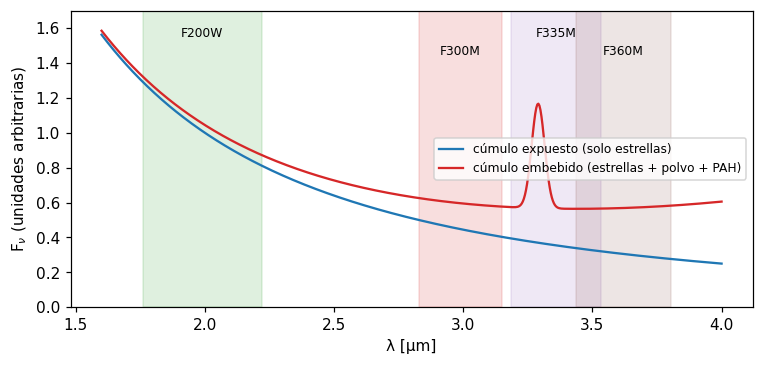

In [6]:
# Esquema (NO es un espectro real): población estelar + polvo + rasgo de PAH a 3.3 µm,
# y la posición aproximada de los filtros de PHANGS.
lam = np.linspace(1.6, 4.0, 600)
estrellas = (lam / 2.0) ** -2.0                                   # cola de Rayleigh-Jeans en F_nu
pah       = 0.6 * np.exp(-0.5 * ((lam - 3.29) / 0.025) ** 2)     # rasgo de 3.3 µm
polvo     = 0.15 * (lam / 3.0) ** 3                               # polvo caliente que sube hacia el rojo

FILTROS_INFO = {  # λ pivote y ancho aproximados (µm)
    "F200W": (1.99, 0.46), "F300M": (2.99, 0.32), "F335M": (3.36, 0.35), "F360M": (3.62, 0.37)}

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lam, estrellas, label="cúmulo expuesto (solo estrellas)", color="tab:blue")
ax.plot(lam, estrellas + polvo + pah, label="cúmulo embebido (estrellas + polvo + PAH)", color="tab:red")
for i, (f, (lp, w)) in enumerate(FILTROS_INFO.items()):
    ax.axvspan(lp - w/2, lp + w/2, color=f"C{i+2}", alpha=0.15)
    ax.text(lp, 1.55 - 0.1*(i % 2), f, ha="center", fontsize=8)
ax.set(xlabel="λ [µm]", ylabel="F$_ν$ (unidades arbitrarias)", ylim=(0, 1.7))
ax.legend(fontsize=8, loc="center right"); plt.show()

✏️ **Preguntas 1**

1. ¿Por qué NIRCam necesita dos canales con distinto tamaño de píxel? (Pista: compara el tamaño de la PSF en F200W y en F360M con el píxel de cada canal; piensa en el muestreo de Nyquist).
2. Con el esquema de arriba: si un cúmulo tiene mucho PAH, ¿será más brillante en F335M o en F300M? En magnitudes, ¿el color F300M−F335M será positivo o negativo?
3. ¿Por qué a 2 µm la extinción por polvo es mucho menor que en el óptico (banda V)? ¿Qué ventaja da eso para estudiar cúmulos que se están formando?

---
## Parte 2 · ¿Cómo se reducen los datos de NIRCam?

No vas a reducir datos, pero sí necesitas saber qué le pasó a la imagen antes de que llegara a tus manos, porque cada paso puede dejar huellas (artefactos) y define las unidades y las incertidumbres.

### El detector: rampas, no exposiciones
Un detector infrarrojo HgCdTe no se «vacía» al leerlo. Durante una integración se lee **muchas veces**; cada lectura (o promedio de lecturas, un *grupo*) mide la carga acumulada. La señal de cada píxel es la **pendiente** de esa rampa (cuentas/s). Ventaja: si un rayo cósmico golpea a mitad de la integración, se ve como un salto en la rampa y se puede corregir sin perder el píxel.

### El pipeline oficial de STScI (`jwst`), en tres etapas

| Etapa | Programa | Entrada → salida | Pasos principales |
|---|---|---|---|
| **1** | `calwebb_detector1` | rampas crudas (`_uncal`) → tasas (`_rate`, cuentas/s) | máscara de píxeles malos, saturación, *superbias*, píxeles de referencia, no linealidad, corriente oscura, **detección de saltos** (rayos cósmicos), **ajuste de rampa** |
| **2** | `calwebb_image2` | `_rate` → imagen calibrada (`_cal`, MJy/sr) | asignación de WCS, **campo plano**, **calibración de flujo** (`photom`) |
| **3** | `calwebb_image3` | muchas `_cal` → **mosaico** (`_i2d`) | alineación astrométrica (`tweakreg`), igualación de cielo (`skymatch`), **rechazo de *outliers*** entre exposiciones con *dithering*, remuestreo (*drizzle*) a una malla común |

### Lo que añade PHANGS (`pjpipe`, Williams et al. 2024)
El equipo envolvió el pipeline oficial con pasos adicionales pensados para galaxias que llenan todo el campo:

* **Ruido 1/f:** la electrónica de lectura deja bandas horizontales/verticales; se modelan y se restan.
* **Fondo:** en una galaxia extendida no hay «cielo vacío» en el campo; los niveles entre baldosas (*tiles*) se igualan y el nivel absoluto se **ancla** a datos externos (por eso archivos internos llevan «anchor» en el nombre).
* **Astrometría:** alineación absoluta a catálogos externos y a las imágenes de PHANGS-HST, de modo que los mosaicos de distintas bandas coinciden.
* Los productos finales son los mosaicos `_img.fits` que usamos aquí.

### Artefactos que todavía puedes encontrar
*Picos de difracción* de seis brazos alrededor de fuentes brillantes · bordes y huecos entre detectores (mapa de pesos) · restos de bandas 1/f · *snowballs* (impactos grandes de rayos cósmicos) · *wisps* y *claws* (luz dispersa en el canal SW).

Ahora vamos a abrir un mosaico y ver estas cosas con nuestros propios ojos.

In [7]:
f0 = FILTROS[0]
with fits.open(RUTAS[f0], memmap=True) as hdul:
    hdul.info()                      # lista de extensiones
    h0  = hdul[0].header.copy()      # encabezado primario: metadatos de la observación
    hsc = hdul["SCI"].header.copy()  # encabezado de la imagen científica

print("\n--- Encabezado primario (selección) ---")
for k in ["TELESCOP", "INSTRUME", "DETECTOR", "FILTER", "PUPIL", "TARGPROP", "DATE-OBS",
          "EFFEXPTM", "CAL_VER", "CRDS_CTX"]:
    print(f"{k:9s} = {h0.get(k, '—')}")
print("\n--- Encabezado SCI (selección) ---")
for k in ["BUNIT", "PIXAR_SR", "PIXAR_A2", "NAXIS1", "NAXIS2", "CTYPE1", "CTYPE2"]:
    print(f"{k:9s} = {hsc.get(k, '—')}")

Filename: datos/hlsp_phangs-jwst_jwst_nircam_ngc0628_f200w_v1p1_img.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     378   ()      
  1  SCI           1 ImageHDU        75   (7289, 9476)   float32   
  2  ERR           1 ImageHDU        10   (7289, 9476)   float32   
  3  CON           1 ImageHDU        10   (7289, 9476, 4)   int32   
  4  WHT           1 ImageHDU         9   (7289, 9476)   float32   
  5  VAR_POISSON    1 ImageHDU         9   (7289, 9476)   float32   
  6  VAR_RNOISE    1 ImageHDU         9   (7289, 9476)   float32   
  7  VAR_FLAT      1 ImageHDU         9   (7289, 9476)   float32   
  8  ASDF          1 BinTableHDU     11   1R x 1C   [541059B]   

--- Encabezado primario (selección) ---
TELESCOP  = JWST
INSTRUME  = NIRCAM
DETECTOR  = MULTIPLE
FILTER    = F200W
PUPIL     = CLEAR
TARGPROP  = NGC-628
DATE-OBS  = 2022-07-17
EFFEXPTM  = 2405.0399999999995
CAL_VER   = 1.13.4
CRDS_CTX  = jwst_1201.pmap

--- Encabezado S

**Extensiones del mosaico:** `SCI` (imagen, MJy/sr), `ERR` (incertidumbre 1σ por píxel), `CON` (*context*: qué exposiciones contribuyen a cada píxel), `WHT` (peso relativo ≈ tiempo de exposición efectivo). `CAL_VER` y `CRDS_CTX` registran la versión del pipeline y de los archivos de referencia: esto es lo que hace **reproducible** una reducción.

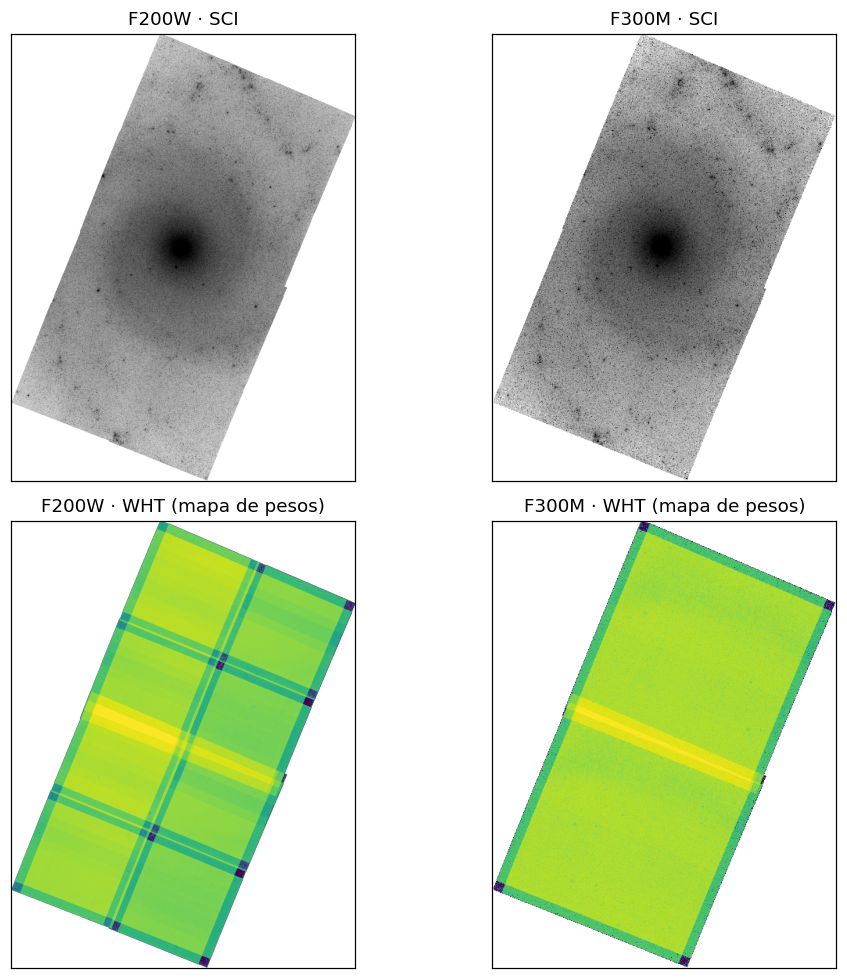

In [8]:
def vista_reducida(ruta, ext, paso=8):
    # Lee una extensión saltando píxeles (para ver el mosaico completo sin agotar la memoria).
    with fits.open(ruta, memmap=True) as hdul:
        try:
            return np.array(hdul[ext].data[::paso, ::paso], dtype=float)
        except KeyError:
            return None

def normalizar(data, pct=99.5, a=0.02):
    return ImageNormalize(data, interval=PercentileInterval(pct), stretch=AsinhStretch(a))

bandas_vista = [FILTROS[0], FILTROS[1]]   # una SW y una LW
fig, axs = plt.subplots(2, 2, figsize=(10, 9))
for j, f in enumerate(bandas_vista):
    sci = vista_reducida(RUTAS[f], "SCI")
    wht = vista_reducida(RUTAS[f], "WHT")
    axs[0, j].imshow(sci, norm=normalizar(sci)); axs[0, j].set_title(f"{f} · SCI")
    if wht is not None:
        w = np.where(wht > 0, wht, np.nan)
        axs[1, j].imshow(w, cmap="viridis", norm=ImageNormalize(w, interval=PercentileInterval(99), stretch=LogStretch()))
    axs[1, j].set_title(f"{f} · WHT (mapa de pesos)")
for a in axs.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

✏️ **Preguntas 2**

1. Compara los mapas de peso de la banda SW y la LW. ¿Por qué la SW muestra un patrón de franjas/huecos que la LW no tiene? (Recuerda cuántos detectores tiene cada canal).
2. ¿Dónde es mayor el peso? ¿Qué significa eso para la incertidumbre de la fotometría de un cúmulo que cae en esa zona?
3. Busca en la imagen SCI un pico de difracción hexagonal y alguna huella de los artefactos listados arriba. ¿Qué podría pasar si haces fotometría de un cúmulo que está sobre un pico de difracción?
4. ¿Por qué el fondo de una imagen de una galaxia cercana es más difícil de estimar que el de un campo extragaláctico vacío?

---
## Parte 3 · Unidades e imágenes en las cuatro bandas

Las imágenes de JWST vienen en **brillo superficial**: MJy sr⁻¹. Para obtener la densidad de flujo de un píxel hay que multiplicar por el ángulo sólido del píxel, Ω_pix (en sr):

$$F_\nu\,[\mathrm{Jy}] = I_\nu\,[\mathrm{MJy\,sr^{-1}}]\times 10^{6}\times \Omega_{\rm pix}\,[\mathrm{sr}]$$

y la magnitud AB es

$$m_{\rm AB} = -2.5\log_{10}\!\left(\frac{F_\nu}{3631\ \mathrm{Jy}}\right).$$

Primero recortamos la misma región del cielo en las cuatro bandas (los mosaicos completos son demasiado grandes para trabajar cómodamente).

In [9]:
# Centro común para todas las bandas
if CENTRO_RECORTE is None:
    with fits.open(RUTAS[FILTROS[0]], memmap=True) as hdul:
        ny, nx = hdul["SCI"].shape
        CENTRO = WCS(hdul["SCI"].header).pixel_to_world(nx / 2, ny / 2)
else:
    CENTRO = SkyCoord(*CENTRO_RECORTE, unit="deg")
print("Centro del recorte:", CENTRO.to_string("hmsdms"))

def cargar_recorte(filt):
    with fits.open(RUTAS[filt], memmap=True) as hdul:
        hsci = hdul["SCI"].header
        w = WCS(hsci)
        cut = Cutout2D(hdul["SCI"].data, CENTRO, TAM_RECORTE, wcs=w, mode="partial", fill_value=np.nan, copy=True)
        try:
            err = Cutout2D(hdul["ERR"].data, CENTRO, TAM_RECORTE, wcs=w, mode="partial",
                           fill_value=np.nan, copy=True).data.astype(float)
        except KeyError:
            err = None
    esc = proj_plane_pixel_scales(cut.wcs) * 3600            # ″/píxel en x e y
    pixar_wcs = ((esc[0] * esc[1]) * u.arcsec**2).to(u.sr).value
    return dict(sci=cut.data.astype(float), err=err, wcs=cut.wcs, escala=float(esc.mean()),
                pixar_sr=pixar_wcs, pixar_hdr=hsci.get("PIXAR_SR"), bunit=hsci.get("BUNIT", "?"))

IMG = {f: cargar_recorte(f) for f in FILTROS}
for f, d in IMG.items():
    print(f"{f}: {d['sci'].shape[1]}×{d['sci'].shape[0]} px | escala {d['escala']:.4f}″/px | "
          f"Ω_pix(WCS) = {d['pixar_sr']:.3e} sr | PIXAR_SR(enc.) = {d['pixar_hdr']} | unidades: {d['bunit']}")

Centro del recorte: 01h36m41.62759338s +15d46m55.26914911s
F200W: 2927×2927 px | escala 0.0307″/px | Ω_pix(WCS) = 2.222e-14 sr | PIXAR_SR(enc.) = 2.22241566090479e-14 | unidades: MJy/sr
F300M: 1428×1428 px | escala 0.0630″/px | Ω_pix(WCS) = 9.331e-14 sr | PIXAR_SR(enc.) = 9.3307355764182e-14 | unidades: MJy/sr
F335M: 1428×1428 px | escala 0.0630″/px | Ω_pix(WCS) = 9.331e-14 sr | PIXAR_SR(enc.) = 9.33119157112682e-14 | unidades: MJy/sr
F360M: 1428×1428 px | escala 0.0630″/px | Ω_pix(WCS) = 9.332e-14 sr | PIXAR_SR(enc.) = 9.3319578155937e-14 | unidades: MJy/sr


In [10]:
def mjysr_a_jy(suma_mjysr, pixar_sr):
    return suma_mjysr * 1e6 * pixar_sr

def jy_a_ab(f_jy):
    f_jy = np.asarray(f_jy, dtype=float)
    return np.where(f_jy > 0, -2.5 * np.log10(np.clip(f_jy, 1e-30, None) / 3631.0), np.nan)

# Ejercicio rápido: ¿cuánto vale en Jy y en mag AB un píxel típico de fondo y uno brillante?
for f, d in IMG.items():
    med = np.nanmedian(d["sci"]); alto = np.nanpercentile(d["sci"], 99.95)
    print(f"{f}: mediana {med:6.3f} MJy/sr → {mjysr_a_jy(med, d['pixar_sr'])*1e9:8.1f} nJy/píxel | "
          f"píxel brillante {alto:7.2f} MJy/sr → m_AB = {jy_a_ab(mjysr_a_jy(alto, d['pixar_sr'])):.2f}")

F200W: mediana  1.708 MJy/sr →     38.0 nJy/píxel | píxel brillante   24.72 MJy/sr → m_AB = 24.55
F300M: mediana  0.906 MJy/sr →     84.6 nJy/píxel | píxel brillante   12.43 MJy/sr → m_AB = 23.74
F335M: mediana  0.832 MJy/sr →     77.6 nJy/píxel | píxel brillante   11.39 MJy/sr → m_AB = 23.83
F360M: mediana  0.745 MJy/sr →     69.5 nJy/píxel | píxel brillante   10.71 MJy/sr → m_AB = 23.90


✏️ ¿Por qué el *mismo* valor en MJy/sr corresponde a un flujo por píxel distinto en F200W y en F300M? Calcula a mano el cociente esperado a partir de las escalas de píxel impresas arriba.

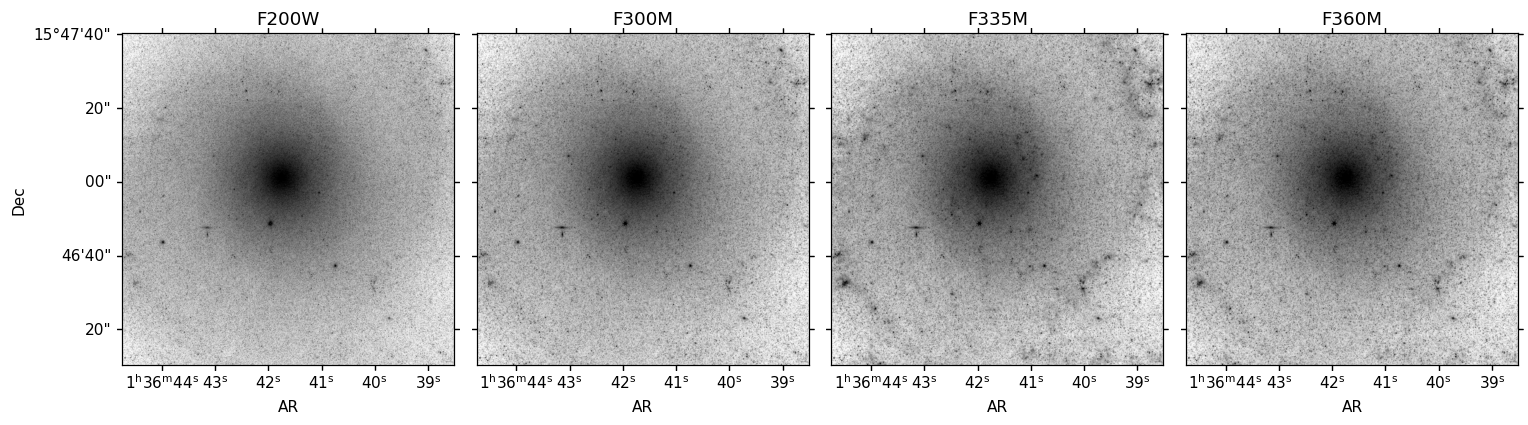

In [11]:
# 🔧 Prueba otros valores de pct (recorte de percentiles) y a (suavidad de la escala asinh)
fig = plt.figure(figsize=(14, 4))
for i, f in enumerate(FILTROS):
    d = IMG[f]
    ax = fig.add_subplot(1, len(FILTROS), i + 1, projection=d["wcs"])
    ax.imshow(d["sci"], norm=normalizar(d["sci"], pct=99.7, a=0.03))
    ax.set_title(f); ax.coords[0].set_axislabel("AR"); ax.coords[1].set_axislabel("Dec" if i == 0 else " ")
    if i > 0: ax.coords[1].set_ticklabel_visible(False)
plt.tight_layout(); plt.show()

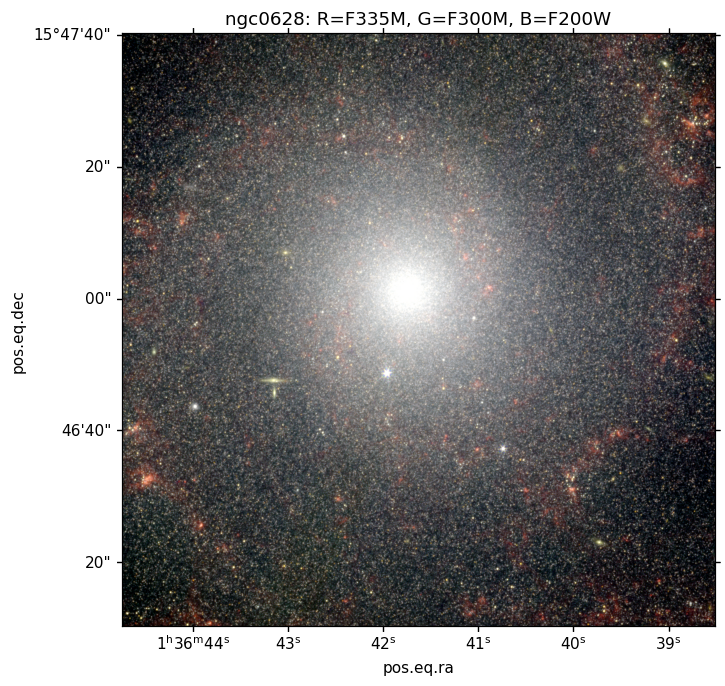

In [12]:
# Imagen en color. Las bandas SW y LW tienen mallas distintas: reproyectamos todo a la malla LW.
from reproject import reproject_interp
ref = IMG[RGB[1]]
def a_malla_ref(f):
    arr, _ = reproject_interp((IMG[f]["sci"], IMG[f]["wcs"]), ref["wcs"], shape_out=ref["sci"].shape)
    return arr

def escalar(x, lo=1, hi=99.7, a=0.05):
    p1, p2 = np.nanpercentile(x, [lo, hi])
    y = np.clip((x - p1) / (p2 - p1), 0, 1)
    return np.arcsinh(y / a) / np.arcsinh(1 / a)

rgb = np.dstack([escalar(a_malla_ref(f)) for f in RGB])
rgb = np.nan_to_num(rgb)
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(projection=ref["wcs"])
ax.imshow(rgb); ax.set_title(f"{GALAXIA}: R={RGB[0]}, G={RGB[1]}, B={RGB[2]}")
plt.show()

✏️ **Preguntas 3**

1. ¿Qué estructuras se ven en F335M que no destacan en F200W? ¿Con qué componente de la galaxia las asociarías?
2. En la imagen RGB, ¿de qué color aparecen las fuentes compactas embebidas en filamentos de polvo? ¿Y los cúmulos o estrellas sin polvo alrededor?
3. ¿Qué compromiso haces al reproyectar F200W a la malla de F300M?

In [13]:
# (Opcional, docente) Guardar recortes pequeños para compartir por Drive en lugar de los mosaicos completos.
GUARDAR_RECORTES = False
if GUARDAR_RECORTES:
    destino = DRIVE_DIR if FUENTE_DATOS == "drive" else LOCAL_DIR
    for f, d in IMG.items():
        hdr = d["wcs"].to_header(); hdr["BUNIT"] = d["bunit"]; hdr["FILTER"] = f
        hdus = [fits.PrimaryHDU(), fits.ImageHDU(d["sci"].astype(np.float32), hdr, name="SCI")]
        if d["err"] is not None:
            hdus.append(fits.ImageHDU(d["err"].astype(np.float32), hdr, name="ERR"))
        ruta = os.path.join(destino, f"{GALAXIA}_{f.lower()}_recorte.fits")
        fits.HDUList(hdus).writeto(ruta, overwrite=True); print("Guardado:", ruta)
    print('Luego usa PATRON_IMAGEN = "{gal}_{filt}_recorte.fits" y CENTRO_RECORTE = None.')

---
## Parte 4 · Fotometría de apertura

La idea es sencilla:

1. Sumar el brillo dentro de un círculo de radio $r_{\rm ap}$ centrado en el cúmulo.
2. Estimar el **fondo local** (la galaxia, no el cielo) en un anillo alrededor, con la mediana con *sigma-clipping* para no contar fuentes vecinas.
3. Restar: $F_{\rm neto} = \sum_{\rm ap} I - \tilde{I}_{\rm anillo}\,N_{\rm pix}$.
4. Corregir por la luz de la PSF que cae **fuera** de la apertura (**corrección de apertura**).

Incertidumbre que usaremos:  $\sigma_F^2 = \sum_{\rm ap}\sigma_{\rm ERR}^2 + N_{\rm pix}^2\,\sigma_{\rm anillo}^2/N_{\rm anillo}$ (ruido de los píxeles + error al estimar el fondo).

Usamos **el mismo radio en segundos de arco** en todas las bandas para medir la misma región física; pero como la PSF es más ancha a mayor λ, la fracción de luz dentro del círculo cambia con la banda. Por eso la corrección de apertura es indispensable para obtener **colores** correctos.

Primero leemos el catálogo.

In [14]:
def a_float(col):
    # Columna (posiblemente enmascarada) → arreglo float con NaN donde falte el dato
    return np.ma.filled(np.ma.asarray(col, dtype=float), np.nan)

def ident(i):
    return FUENTES[COLS["id"]][i] if COLS["id"] in FUENTES.colnames else i

def leer_tabla(ruta):
    try:
        return Table.read(ruta)
    except Exception:
        return Table.read(ruta, format="ascii")

HAY_CATALOGO = ARCHIVO_CATALOGO is not None
if HAY_CATALOGO:
    CAT = leer_tabla(resolver(ARCHIVO_CATALOGO))
    print(f"{len(CAT)} filas. Columnas disponibles:\n{CAT.colnames}\n")
    necesarias = [COLS["ra"], COLS["dec"]] + list(COLS["mag"].values())
    faltan = [c for c in necesarias if c not in CAT.colnames]
    if faltan:
        print("⚠️ Estas columnas de COLS no existen en el catálogo:", faltan)
        for f in FILTROS:
            print(f"   candidatas para {f}:", [c for c in CAT.colnames if f.lower() in c.lower()])
        raise KeyError("Ajusta el diccionario COLS en la celda de configuración y vuelve a correr.")
    CAT[:5].pprint(max_width=150)
else:
    print("Sin catálogo: detectaremos fuentes en", FILTROS[0])

FileNotFoundError: catalogo_nircam.fits no está en MAST. Revisa GALAXIA y PATRON_IMAGEN.

In [ ]:
d0 = IMG[FILTROS[0]]
ny, nx = d0["sci"].shape

if HAY_CATALOGO:
    coords_all = SkyCoord(CAT[COLS["ra"]], CAT[COLS["dec"]], unit="deg")
    x, y = d0["wcs"].world_to_pixel(coords_all)
    dentro = (x > 20) & (x < nx - 20) & (y > 20) & (y < ny - 20)
    FUENTES = CAT[dentro]
    COORDS = coords_all[dentro]
else:
    # Detección sencilla: restar un fondo suave y buscar picos ~ PSF
    from photutils.background import Background2D, MedianBackground
    from photutils.detection import DAOStarFinder
    sci = d0["sci"]; ok = np.isfinite(sci)
    bkg = Background2D(np.where(ok, sci, 0), box_size=64, filter_size=3,
                       coverage_mask=~ok, fill_value=0.0, bkg_estimator=MedianBackground())
    resta = np.where(ok, sci - bkg.background, 0)
    _, _, std = sigma_clipped_stats(resta[ok], sigma=3)
    fwhm_px = 0.07 / d0["escala"]
    src = DAOStarFinder(fwhm=fwhm_px, threshold=8 * std, exclude_border=True)(resta)
    src.sort("flux", reverse=True); src = src[:400]
    COORDS = d0["wcs"].pixel_to_world(src["xcentroid"], src["ycentroid"])
    FUENTES = Table({"ID": np.arange(len(src)), "RA": COORDS.ra.deg, "DEC": COORDS.dec.deg})
    COLS.update(id="ID", ra="RA", dec="DEC")

print(f"{len(FUENTES)} fuentes dentro del recorte.")
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(projection=d0["wcs"])
ax.imshow(d0["sci"], norm=normalizar(d0["sci"], 99.7, 0.03))
xs, ys = d0["wcs"].world_to_pixel(COORDS)
ax.scatter(xs, ys, s=25, facecolor="none", edgecolor="tab:red", lw=0.7)
ax.set_title(f"Fuentes sobre {FILTROS[0]}"); plt.show()

In [ ]:
# 🔧 Radios en segundos de arco (los mismos para todas las bandas)
R_AP, R_IN, R_OUT = 0.20, 0.35, 0.50

def fotometria(filt, coords, r_ap=R_AP, r_in=R_IN, r_out=R_OUT):
    d = IMG[filt]; s = d["escala"]
    x, y = d["wcs"].world_to_pixel(coords)
    pos = np.column_stack([np.atleast_1d(x), np.atleast_1d(y)])
    mask = ~np.isfinite(d["sci"])
    if d["err"] is not None:
        mask |= ~np.isfinite(d["err"])
    ap = CircularAperture(pos, r=r_ap / s)
    an = CircularAnnulus(pos, r_in=r_in / s, r_out=r_out / s)
    st = ApertureStats(d["sci"], an, mask=mask, sigma_clip=SigmaClip(sigma=3.0))
    bkg, sbkg = np.asarray(st.median), np.asarray(st.std)
    n_an = np.asarray(getattr(st.sum_aper_area, "value", st.sum_aper_area))
    t = aperture_photometry(d["sci"], ap, error=d["err"], mask=mask)
    area = np.asarray(ap.area_overlap(d["sci"], mask=mask))
    neto = np.asarray(t["aperture_sum"]) - bkg * area
    var_pix = np.asarray(t["aperture_sum_err"]) ** 2 if d["err"] is not None else area * sbkg**2
    sig = np.sqrt(var_pix + area**2 * sbkg**2 / np.clip(n_an, 1, None))
    f_jy, e_jy = mjysr_a_jy(neto, d["pixar_sr"]), mjysr_a_jy(sig, d["pixar_sr"])
    mag = jy_a_ab(f_jy)
    emag = np.where(f_jy > 0, 2.5 / np.log(10) * e_jy / np.abs(f_jy), np.nan)
    return dict(flujo_jy=f_jy, eflujo_jy=e_jy, mag=mag, emag=emag, fondo=bkg)

# Ejemplo con las 5 primeras fuentes
for f in FILTROS:
    r = fotometria(f, COORDS[:5])
    print(f, np.round(r["mag"], 2), "±", np.round(r["emag"], 3))

### Curva de crecimiento y corrección de apertura
Medimos el flujo de fuentes brillantes y **aisladas** en radios cada vez mayores. La curva se aplana cuando el círculo contiene casi toda la luz. La corrección es
$\Delta m_{\rm ap} = -2.5\log_{10}\left[F(r_{\rm ap})/F(r_{\rm grande})\right]$ (negativa: hay que hacer la fuente más brillante).

In [ ]:
radios = np.arange(0.04, 0.62, 0.04)   # ″

# Fuentes brillantes y aisladas (vecino más cercano a > 1″)
_, sep, _ = COORDS.match_to_catalog_sky(COORDS, nthneighbor=2)
m0 = fotometria(FILTROS[0], COORDS)["mag"]
cand = np.where((sep.arcsec > 1.0) & np.isfinite(m0))[0]
brillantes = cand[np.argsort(m0[cand])][:15]
print(f"Usando {len(brillantes)} fuentes brillantes y aisladas.")

APCORR = {}
fig, ax = plt.subplots(figsize=(6.5, 4))
for f in FILTROS:
    curvas = np.array([fotometria(f, COORDS[brillantes], r_ap=r, r_in=0.7, r_out=1.0)["flujo_jy"] for r in radios]).T
    frac = curvas / curvas[:, [-1]]
    med = np.nanmedian(frac, axis=0)
    ax.plot(radios, med, "o-", ms=3, label=f)
    APCORR[f] = -2.5 * np.log10(np.interp(R_AP, radios, med))
ax.axvline(R_AP, ls="--", c="k", lw=0.8); ax.axhline(1, c="gray", lw=0.5)
ax.set(xlabel="radio [″]", ylabel=f"F(r) / F({radios[-1]:.2f}″)", title="Curva de crecimiento (mediana)")
ax.legend(); plt.show()
for f in FILTROS:
    print(f"Corrección de apertura {f} (r = {R_AP}″ → {radios[-1]:.2f}″): {APCORR[f]:+.3f} mag")

> Esta corrección **empírica** solo lleva la apertura hasta ≈0.6″. Los catálogos profesionales suelen añadir una corrección a radio infinito calculada con modelos de PSF (p. ej. con STPSF/WebbPSF). Además, los cúmulos están **ligeramente resueltos** a la distancia de estas galaxias, así que su curva de crecimiento no es exactamente la de una estrella: la elección de las fuentes «de referencia» importa.

In [ ]:
FOT = {f: fotometria(f, COORDS) for f in FILTROS}
MAG_NUESTRA  = {f: FOT[f]["mag"] + APCORR[f] for f in FILTROS}
EMAG_NUESTRA = {f: FOT[f]["emag"] for f in FILTROS}

if HAY_CATALOGO:
    fig, axs = plt.subplots(1, len(FILTROS), figsize=(15, 3.6), sharey=True)
    for ax, f in zip(axs, FILTROS):
        mc = a_float(FUENTES[COLS["mag"][f]])
        dm = MAG_NUESTRA[f] - mc
        ok = np.isfinite(dm) & np.isfinite(mc)
        med = np.nanmedian(dm[ok]); mad = 1.4826 * np.nanmedian(np.abs(dm[ok] - med))
        ax.scatter(mc[ok], dm[ok], s=4, alpha=0.5)
        ax.axhline(0, c="k", lw=0.6); ax.axhline(med, c="tab:red", lw=1)
        ax.set(title=f"{f}: Δ = {med:+.2f}, σ = {mad:.2f}", xlabel="m catálogo [AB]", ylim=(-1, 1))
    axs[0].set_ylabel("m nuestra − m catálogo")
    plt.tight_layout(); plt.show()

✏️ **Preguntas 4**

1. ¿Por qué la corrección de apertura es más grande (en valor absoluto) en F360M que en F200W?
2. Si olvidaras la corrección de apertura, ¿en qué sentido se sesgaría el color F200W−F360M?
3. Compara tu fotometría con la del catálogo. ¿Hay un desplazamiento sistemático? Enumera al menos tres razones posibles (radio, fondo, corrección a infinito, extinción galáctica, distinto centrado…).
4. ¿Por qué la dispersión crece hacia magnitudes débiles? ¿Qué otro efecto agranda la dispersión en las zonas con mucho polvo y emisión difusa?
5. 🔧 Cambia `R_AP` a 0.12″ y a 0.35″ y vuelve a correr la Parte 4. ¿Qué pasa con la dispersión respecto al catálogo y por qué?

---
## Parte 5 · El catálogo: magnitudes y colores

A partir de aquí usamos las magnitudes del **catálogo** (si no hay catálogo, las nuestras corregidas por apertura).

In [ ]:
if HAY_CATALOGO:
    MAG  = {f: a_float(FUENTES[COLS["mag"][f]]) for f in FILTROS}
    EMAG = {f: (a_float(FUENTES[COLS["err"][f]]) if COLS["err"][f] in FUENTES.colnames
                else EMAG_NUESTRA[f]) for f in FILTROS}
else:
    MAG  = {f: MAG_NUESTRA[f].copy() for f in FILTROS}
    EMAG = {f: EMAG_NUESTRA[f].copy() for f in FILTROS}

# Valores centinela típicos (99, -99, etc.) → NaN
for f in FILTROS:
    malo = ~np.isfinite(MAG[f]) | (MAG[f] > 40) | (MAG[f] < 5)
    MAG[f][malo] = np.nan; EMAG[f][malo] = np.nan

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for f in FILTROS:
    axs[0].hist(MAG[f][np.isfinite(MAG[f])], bins=40, histtype="step", label=f)
    axs[1].scatter(MAG[f], EMAG[f], s=3, alpha=0.5, label=f)
axs[0].set(xlabel="m [AB]", ylabel="N", title="Distribución de magnitudes"); axs[0].legend()
axs[1].set(xlabel="m [AB]", ylabel="σ_m", yscale="log", title="Error vs. magnitud")
plt.tight_layout(); plt.show()

✏️ ¿Dónde «se cae» el histograma de cada banda? Usa ese punto y la gráfica de error para estimar la **completitud** aproximada y la magnitud a la que σ_m ≈ 0.1 (S/N ≈ 10). ¿Qué banda llega más profundo? ¿Por qué?

In [ ]:
# 🔧 Corte de calidad
EMAX = 0.15
k, m3, m335, m36 = (MAG[f] for f in FILTROS)
ek, e3, e335, e36 = (EMAG[f] for f in FILTROS)
bueno = np.isfinite(k + m3 + m335 + m36) & (ek < EMAX) & (e3 < EMAX) & (e335 < EMAX) & (e36 < EMAX)
print(f"{bueno.sum()} fuentes con σ < {EMAX} en las cuatro bandas.")

K_F300M   = k - m3        # = F200W − F300M
PAH_COLOR = m3 - m335     # > 0 → exceso en F335M (PAH)
F335_F360 = m335 - m36

# Clases del catálogo (si existen) para colorear los puntos
if COLS["clase"] and COLS["clase"] in FUENTES.colnames:
    clase = np.asarray(FUENTES[COLS["clase"]]).astype(str)
else:
    clase = None

fig, ax = plt.subplots(figsize=(5.5, 5.5))
if clase is None:
    ax.scatter(K_F300M[bueno], k[bueno], s=6, alpha=0.6)
else:
    for c in np.unique(clase[bueno]):
        s = bueno & (clase == c); ax.scatter(K_F300M[s], k[s], s=6, alpha=0.7, label=c)
    ax.legend(title=COLS["clase"], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="K−F300M [AB]", ylabel="F200W [AB]", title="Diagrama color–magnitud")
plt.show()

In [ ]:
# Vector de enrojecimiento APROXIMADO: ley de potencia A_λ/A_V ≈ 0.11 (λ/2.2 µm)^-1.7 (solo ilustrativo; 🔧 cámbiala)
LPIV = {"F200W": 1.99, "F300M": 2.99, "F335M": 3.36, "F360M": 3.62}
def A_sobre_AV(lam_um): return 0.11 * (lam_um / 2.2) ** -1.7
AV = 10.0
dx = AV * (A_sobre_AV(LPIV["F200W"]) - A_sobre_AV(LPIV["F300M"]))
dy = AV * (A_sobre_AV(LPIV["F300M"]) - A_sobre_AV(LPIV["F335M"]))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(K_F300M[bueno], PAH_COLOR[bueno], c=k[bueno], s=8, cmap="viridis_r")
plt.colorbar(sc, label="F200W [AB]")
x0, y0 = np.nanpercentile(K_F300M[bueno], 5), np.nanpercentile(PAH_COLOR[bueno], 95)
ax.annotate("", xy=(x0 + dx, y0 + dy), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(x0, y0 + 0.05, f"A$_V$ = {AV:.0f} (aprox.)", fontsize=8)
ax.axhline(0, c="gray", lw=0.5)
ax.set(xlabel="K−F300M [AB]", ylabel="F300M−F335M [AB]", title="Diagrama color–color")
plt.show()

**Cómo leer el diagrama color–color**

* **Abajo a la izquierda:** colores de una población estelar sin polvo. En AB, la cola de Rayleigh-Jeans hace que K−F300M sea negativo (más brillante en flujo a 2 µm que a 3 µm).
* **Hacia la derecha:** el cúmulo se enrojece en K−F300M por **extinción** (flecha) y/o por **polvo caliente** que emite a 3 µm.
* **Hacia arriba:** **exceso en F335M** → emisión de PAH a 3.3 µm. Es la firma de un cúmulo joven todavía rodeado por su nube natal (unos pocos Myr).

✏️ **Preguntas 5**

1. ¿Las fuentes más rojas en K−F300M se pueden explicar *solo* con extinción? Usa la flecha para argumentar.
2. Propón un criterio sencillo (cortes en los dos colores) para seleccionar candidatos a cúmulos embebidos. ¿Cuántos obtienes?
3. ¿Dónde caen en el diagrama color–magnitud esos candidatos? ¿Son más brillantes o más débiles que el resto en F200W? ¿Por qué podría ser?
4. Un cúmulo viejo (>100 Myr) ¿debería mostrar exceso de PAH? ¿Por qué podría aparecer de todos modos un exceso en F335M en una fuente vieja? (Pista: piensa en la apertura y en el fondo de la galaxia).

---
## Parte 6 · Un cúmulo, cuatro bandas

Elegimos automáticamente los tres objetos con mayor exceso de PAH (probablemente **embebidos**) y los tres más azules en K−F300M entre los brillantes (probablemente **expuestos**), y los miramos en cada banda.

In [ ]:
idx_b = np.where(bueno)[0]
emb  = idx_b[np.argsort(PAH_COLOR[idx_b])[::-1][:3]]
brill = idx_b[k[idx_b] < np.nanpercentile(k[idx_b], 50)]
exp_ = brill[np.argsort(K_F300M[brill])[:3]]
EJEMPLOS = [(i, "embebido?") for i in emb] + [(i, "expuesto?") for i in exp_]

TAM_SELLO = 3.0 * u.arcsec   # 🔧
fig, axs = plt.subplots(len(EJEMPLOS), len(FILTROS), figsize=(2.3 * len(FILTROS), 2.3 * len(EJEMPLOS)))
for r, (i, etiqueta) in enumerate(EJEMPLOS):
    for c, f in enumerate(FILTROS):
        d = IMG[f]
        sello = Cutout2D(d["sci"], COORDS[i], TAM_SELLO, wcs=d["wcs"], mode="partial", fill_value=np.nan).data
        lo, hi = np.nanpercentile(sello, [5, 99.9])
        axs[r, c].imshow(sello, norm=ImageNormalize(vmin=lo, vmax=hi, stretch=AsinhStretch(0.1)))
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
        if r == 0: axs[r, c].set_title(f)
    axs[r, 0].set_ylabel(f"#{ident(i)}\n{etiqueta}\nK−F300M={K_F300M[i]:.2f}\nPAH={PAH_COLOR[i]:.2f}", fontsize=7)
plt.suptitle(f"Sellos de {TAM_SELLO.value:.0f}″ (cada uno con su propia escala)", y=1.0)
plt.tight_layout(); plt.show()

In [ ]:
def perfil_radial(d, coord, rmax=0.6, dr=None):
    s = d["escala"]; dr = dr or s
    sello = Cutout2D(d["sci"], coord, 2 * rmax * u.arcsec, wcs=d["wcs"], mode="partial", fill_value=np.nan)
    y, x = np.indices(sello.data.shape)
    xc, yc = sello.wcs.world_to_pixel(coord)
    r = np.hypot(x - xc, y - yc) * s
    bordes = np.arange(0, rmax + dr, dr); rc = 0.5 * (bordes[1:] + bordes[:-1])
    perf = np.array([np.nanmean(sello.data[(r >= a) & (r < b)]) for a, b in zip(bordes[:-1], bordes[1:])])
    perf = perf - np.nanmin(perf)
    return rc, perf / np.nanmax(perf)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (i, etiqueta) in zip(axs, [EJEMPLOS[0], EJEMPLOS[3]]):
    for f in FILTROS:
        rc, p = perfil_radial(IMG[f], COORDS[i]); ax.plot(rc, p, label=f)
    ax.set(xlabel="radio [″]", title=f"#{ident(i)} ({etiqueta})")
axs[0].set_ylabel("brillo normalizado"); axs[0].legend(); plt.tight_layout(); plt.show()

✏️ **Preguntas 6**

1. Describe con tus palabras cómo cambia la apariencia del cúmulo «embebido» de F200W a F335M. ¿Ves estructura extendida (arcos, cáscaras, filamentos) en F335M?
2. ¿El cúmulo «expuesto» se ve parecido en las cuatro bandas? ¿Qué cambia y por qué (piensa en la PSF)?
3. En los perfiles radiales: ¿qué parte del ensanchamiento con λ se debe a la PSF y qué parte a emisión extendida real? ¿Cómo podrías separarlas?
4. ¿Qué implicaciones tiene la emisión extendida de PAH alrededor de un cúmulo para la fotometría de apertura (fondo en el anillo, flujo en la apertura)?
5. Si tuvieras imágenes de HST (UV–óptico) del mismo campo, ¿esperarías ver el cúmulo embebido? ¿Y el expuesto? ¿Qué te diría eso sobre la secuencia evolutiva de los cúmulos?

---
## Extensión opcional · Comparar con modelos de poblaciones estelares simples

Si tienes una tabla de modelos (una fila por edad, magnitudes AB en las mismas bandas), puedes superponerla al diagrama color–color. Pon la ruta en `MODELOS` y ajusta los nombres de columnas.

In [ ]:
MODELOS = None                       # p. ej. "modelos_ssp.csv" (en DRIVE_DIR) o ruta absoluta
COL_EDAD = "age"                     # columna de edad
COLS_MOD = {f: f for f in FILTROS}   # columnas de magnitud de cada banda en la tabla de modelos

if MODELOS:
    mod = leer_tabla(resolver(MODELOS))
    mk, m3m, m335m = (np.asarray(mod[COLS_MOD[f]], float) for f in FILTROS[:3])
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(K_F300M[bueno], PAH_COLOR[bueno], s=6, c="0.6", label="observado")
    sc = ax.scatter(mk - m3m, m3m - m335m, c=np.log10(np.asarray(mod[COL_EDAD], float)), s=12, cmap="plasma", label="modelos")
    plt.colorbar(sc, label=f"log({COL_EDAD})")
    ax.set(xlabel="K−F300M [AB]", ylabel="F300M−F335M [AB]"); ax.legend(); plt.show()

✏️ Los modelos de poblaciones estelares sin polvo, ¿pueden alcanzar la región de exceso de PAH? ¿Qué ingredientes les faltarían?

---
## Para entregar
Un informe breve (2–3 páginas) con: (i) respuestas a las preguntas, (ii) las figuras de la curva de crecimiento, la comparación con el catálogo y el diagrama color–color, (iii) tu criterio de selección de cúmulos embebidos y el número de candidatos encontrados.

## Referencias
* Lee, J. C. et al. 2023, *ApJL* — PHANGS-JWST: presentación del programa.
* Williams, T. G. et al. 2024, *ApJS* — `pjpipe`, el pipeline de PHANGS-JWST.
* Rodríguez, M. J. et al. 2023, *ApJL* — cúmulos embebidos seleccionados con PAH en PHANGS-JWST.
* JWST User Documentation (JDox): NIRCam y el pipeline de calibración — https://jwst-docs.stsci.edu
* Datos: PHANGS-JWST HLSP en MAST — https://archive.stsci.edu/hlsp/phangs/phangs-jwst (DOI 10.17909/ew88-jt15)